## Experiment 14 — OOD Detection with Energy and Mahalanobis Distance

### Motivation

The trained ResNet18 model is designed to classify images into eight known vehicle classes. However, the model is not explicitly trained to recognize unseen classes. Therefore, when an image from an unseen class such as `neysan` is given to the model, the softmax layer will still assign probabilities to the eight known classes.

For example, even if an image does not belong to any of the known classes, the model may still produce a prediction such as:

```text
kamyun     0.43
kamyunet   0.31

```

This happens because softmax normalizes the output logits across the available classes and always produces a probability distribution over these eight classes. Therefore, **softmax confidence alone cannot reliably determine whether an input belongs to a known or unseen class**.

To address this issue, two Out-of-Distribution (OOD) detection methods were investigated:

1. Energy Score
2. Mahalanobis Distance

The goal is to determine whether an input image is sufficiently different from the known training distribution and should therefore be treated as an unseen sample.

### Energy Score

The Energy Score is computed directly from the model's output logits:

$$
E(x) = -T \log \sum_i \exp\left(\frac{f_i(x)}{T}\right)
$$

where:

* $f_i(x)$ is the logit corresponding to class $i$.
* $T$ is the temperature parameter.
* $E(x)$ is the energy score.

With this formulation, lower energy values generally indicate that the input is more consistent with the known classes, while higher energy values indicate that the input may be out-of-distribution.

Therefore, an unseen `neysan` image is expected to produce a relatively higher energy score than images belonging to the known vehicle classes.

### Mahalanobis Distance

The Mahalanobis method uses the feature representation learned by the ResNet18 backbone rather than the final classification probabilities.

For each input image, the feature vector is extracted from the layer immediately before the final fully connected classifier:

```text
Input Image
     ↓
ResNet18 Backbone
     ↓
512-dimensional Feature Vector
     ↓
Fully Connected Layer
     ↓
8 Class Logits
```

For each known class, the mean feature vector is calculated from the training samples:

```text
ambulance → μ₀
autobus   → μ₁
kamyun    → μ₂
kamyunet  → μ₃
minibus   → μ₄
savari    → μ₅
taxi      → μ₆
vanet     → μ₇
```

The Mahalanobis distance between an input feature vector $x$ and class $k$ is calculated as:

$$
D_k(x) =
\sqrt{
(x-\mu_k)^T
\Sigma^{-1}
(x-\mu_k)
}
$$

where:

* $x$ is the feature vector of the input image.
* $\mu_k$ is the mean feature vector of class $k$.
* $\Sigma$ is the covariance matrix of the feature space.
* $\Sigma^{-1}$ is the inverse covariance matrix.

The final Mahalanobis score is defined as the distance to the closest known class:

$$
D(x) = \min_k D_k(x)
$$

A small distance indicates that the input is close to at least one known class in the learned feature space. In contrast, a large distance indicates that the input is far from all known classes and is therefore more likely to be an OOD sample.

### OOD Detection Procedure

The ResNet18 model remains an eight-class classifier throughout this experiment. The `neysan` class is **not added as a ninth classification class**.

The OOD detection procedure is performed as follows:

1. Extract feature representations from the known training samples.
2. Calculate the mean feature vector for each known class.
3. Estimate the covariance matrix of the feature space.
4. Calculate Energy and Mahalanobis scores for the validation samples.
5. Select OOD thresholds using only the known validation data.
6. Apply the selected thresholds to the unseen `neysan` samples.
7. Mark an image as `OOD` when its score exceeds the corresponding threshold.

This prevents the unseen `neysan` samples from being used to select the detection threshold.

### Threshold Selection

The detection threshold should be determined using the validation set rather than the unseen `neysan` images. For example, the threshold can be selected so that approximately 95% of known validation samples are accepted as in-distribution samples.

This allows the `neysan` dataset to be used only for the final evaluation of OOD detection performance.

### Expected Behavior

The desired behavior is not necessarily to assign `neysan` to one of the eight known classes. Instead, the model should be able to recognize when an input is sufficiently different from the known training distribution.

The final decision can therefore be represented as:

```text

Input Image
     ↓
ResNet18
     ↓
Known-class prediction
     ↓
OOD Detection
     ↓
 ┌───────────────┐
 │               │
Known           OOD
 │               │
 ↓               ↓
Return class    Unknown / Needs Review

```

This approach allows the original eight-class classifier to remain unchanged while adding a separate mechanism for detecting potentially unseen vehicle types.



This happens because softmax normalizes the output logits across the available classes and always produces a probability distribution over these eight classes. Therefore, **softmax confidence alone cannot reliably determine whether an input belongs to a known or unseen class**.

To address this issue, two Out-of-Distribution (OOD) detection methods were investigated:

1. Energy Score
2. Mahalanobis Distance

The goal is to determine whether an input image is sufficiently different from the known training distribution and should therefore be treated as an unseen sample.

### Energy Score

The Energy Score is computed directly from the model's output logits:

$$
E(x) = -T \log \sum_i \exp\left(\frac{f_i(x)}{T}\right)
$$

where:

* $f_i(x)$ is the logit corresponding to class $i$.
* $T$ is the temperature parameter.
* $E(x)$ is the energy score.

With this formulation, lower energy values generally indicate that the input is more consistent with the known classes, while higher energy values indicate that the input may be out-of-distribution.

Therefore, an unseen `neysan` image is expected to produce a relatively higher energy score than images belonging to the known vehicle classes.

### Mahalanobis Distance

The Mahalanobis method uses the feature representation learned by the ResNet18 backbone rather than the final classification probabilities.

For each input image, the feature vector is extracted from the layer immediately before the final fully connected classifier:

```text
Input Image
     ↓
ResNet18 Backbone
     ↓
512-dimensional Feature Vector
     ↓
Fully Connected Layer
     ↓
8 Class Logits
```

For each known class, the mean feature vector is calculated from the training samples:

```text
ambulance → μ₀
autobus   → μ₁
kamyun    → μ₂
kamyunet  → μ₃
minibus   → μ₄
savari    → μ₅
taxi      → μ₆
vanet     → μ₇
```

The Mahalanobis distance between an input feature vector $x$ and class $k$ is calculated as:

$$
D_k(x) =
\sqrt{
(x-\mu_k)^T
\Sigma^{-1}
(x-\mu_k)
}
$$

where:

* $x$ is the feature vector of the input image.
* $\mu_k$ is the mean feature vector of class $k$.
* $\Sigma$ is the covariance matrix of the feature space.
* $\Sigma^{-1}$ is the inverse covariance matrix.

The final Mahalanobis score is defined as the distance to the closest known class:

$$
D(x) = \min_k D_k(x)
$$

A small distance indicates that the input is close to at least one known class in the learned feature space. In contrast, a large distance indicates that the input is far from all known classes and is therefore more likely to be an OOD sample.

### OOD Detection Procedure

The ResNet18 model remains an eight-class classifier throughout this experiment. The `neysan` class is **not added as a ninth classification class**.

The OOD detection procedure is performed as follows:

1. Extract feature representations from the known training samples.
2. Calculate the mean feature vector for each known class.
3. Estimate the covariance matrix of the feature space.
4. Calculate Energy and Mahalanobis scores for the validation samples.
5. Select OOD thresholds using only the known validation data.
6. Apply the selected thresholds to the unseen `neysan` samples.
7. Mark an image as `OOD` when its score exceeds the corresponding threshold.

This prevents the unseen `neysan` samples from being used to select the detection threshold.

### Threshold Selection

The detection threshold should be determined using the validation set rather than the unseen `neysan` images. For example, the threshold can be selected so that approximately 95% of known validation samples are accepted as in-distribution samples.

This allows the `neysan` dataset to be used only for the final evaluation of OOD detection performance.

### Expected Behavior

The desired behavior is not necessarily to assign `neysan` to one of the eight known classes. Instead, the model should be able to recognize when an input is sufficiently different from the known training distribution.

The final decision can therefore be represented as:

```text
Input Image
     ↓
ResNet18
     ↓
Known-class prediction
     ↓
OOD Detection
     ↓
 ┌───────────────┐
 │               │
Known           OOD
 │               │
 ↓               ↓
Return class    Unknown / Needs Review
```

This approach allows the original eight-class classifier to remain unchanged while adding a separate mechanism for detecting potentially unseen vehicle types.

```
```


In [1]:
from pathlib import Path
import sys
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np

from torch.utils.data import DataLoader,Dataset
from torchvision.datasets import ImageFolder
from torchvision import datasets, transforms
from torchvision import models
from torchvision.models import resnet18, ResNet18_Weights
from torchvision import transforms
from PIL import Image

from sklearn.metrics import classification_report


from sklearn.covariance import LedoitWolf
from sklearn.metrics import classification_report, confusion_matrix

# Project root
PROJECT_DIR = Path.cwd().parent

if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

sys.path.append("../src")

from data import (
    letterbox,
    create_train_val_datasets,
    create_dataloaders,
    predict_images
)

from models import SimpleCNN

from train import train_model

from utils import (
    get_predictions,
    plot_confusion_matrix,
    get_classification_report,
    plot_training_history,
    set_seed
)
from data import (
    letterbox,
    create_train_val_datasets,
    create_dataloaders
)

In [2]:
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

UNSEEN_DIR = PROJECT_DIR / "dataset" / "neysan"
TEST_DIR = PROJECT_DIR / "dataset" / "test"
MERGED_TRAIN_DIR = PROJECT_DIR / "dataset" / "merged_train"
CHECKPOINT_PATH = PROJECT_DIR / "checkpoints" /"resnet18_full_finetuning_non_letterbox_best.pt" 

In [3]:
test_transform = transforms.Compose([
    transforms.Lambda(
        lambda img: letterbox(
            img,
            target_size=(224, 224)
        )
    ),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])


test_dataset = ImageFolder(
    TEST_DIR,
    transform=test_transform
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False
)


train_dataset, val_dataset, train_indices, val_indices, class_to_idx = \
    create_train_val_datasets(
        data_dir=MERGED_TRAIN_DIR,
        train_transform = test_transform,
        val_transform=test_transform,
        test_size=0.2,
        seed=7,
    )

train_loader, val_loader = create_dataloaders(
    train_dataset=train_dataset,
    val_dataset=val_dataset,
    batch_size=32,
    shuffle_train=True,
)

full_dataset = datasets.ImageFolder(MERGED_TRAIN_DIR)
class_names = full_dataset.classes

print("Train:", len(train_dataset), "Val:", len(val_dataset))
print("Classes:", class_names)


Train: 2713 Val: 679
Classes: ['ambulance', 'autobus', 'kamyun', 'kamyunet', 'minibus', 'savari', 'taxi', 'vanet']


### Load The Best Model's Checkpoint

In [4]:
checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=DEVICE
)

model = models.resnet18(
    weights=ResNet18_Weights.DEFAULT
)

model.fc = nn.Linear(
    model.fc.in_features,
    8
)

model.load_state_dict(
    checkpoint["model_state_dict"]
)

model = model.to(DEVICE)
model = model.eval()

### Extract Features From Resnet 18

In [5]:
def extract_features(model, x):
    x = model.conv1(x)
    x = model.bn1(x)
    x = model.relu(x)
    x = model.maxpool(x)

    x = model.layer1(x)
    x = model.layer2(x)
    x = model.layer3(x)
    x = model.layer4(x)

    x = model.avgpool(x)

    x = torch.flatten(x, 1)

    return x

### Creating a feature bank from the training set

In [6]:
def collect_features(model, dataloader, device):
    model.eval()

    all_features = []
    all_labels = []

    with torch.no_grad():
        for images, labels in dataloader:
            images = images.to(device)

            features = extract_features(model, images)

            all_features.append(features.cpu())
            all_labels.append(labels)

    all_features = torch.cat(all_features)
    all_labels = torch.cat(all_labels)

    return all_features, all_labels

In [7]:
train_loader_features = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=False,
    num_workers=0
)

train_features, train_labels = collect_features(
    model,
    train_loader_features,
    DEVICE
)

print(train_features.shape)
print(train_labels.shape)

torch.Size([2713, 512])
torch.Size([2713])


### Calculating Mean in Each Class

In [8]:
class_means = []
NUM_CLASSES = 8

for class_idx in range(NUM_CLASSES):

    class_features = train_features[
        train_labels == class_idx
    ]

    mean = class_features.mean(dim=0)

    class_means.append(mean)

class_means = torch.stack(class_means)

print(class_means.shape)

torch.Size([8, 512])


### Covariance Estimation

The Mahalanobis distance requires the inverse of the covariance matrix of the feature space. Since the ResNet18 feature representation has 512 dimensions, directly estimating and inverting the covariance matrix can be numerically unstable, especially when the number of training samples is not sufficiently large compared with the feature dimensionality.

To obtain a more stable covariance estimate, **Ledoit-Wolf shrinkage** was used. This method regularizes the covariance estimate by shrinking it toward a more stable target matrix, which improves numerical stability when computing its inverse.

The covariance matrix was estimated using the feature vectors extracted from the known training classes:


In [9]:
lw = LedoitWolf()

lw.fit(train_features.numpy())

covariance = lw.covariance_

precision = np.linalg.inv(covariance)

precision = torch.tensor(
    precision,
    dtype=torch.float32
)

Here, `covariance` represents the estimated covariance matrix of the 512-dimensional feature space, while `precision` represents its inverse:

$$
\text{precision} = \Sigma^{-1}
$$

The inverse covariance matrix is then used in the Mahalanobis distance calculation to account for the correlation and scale of different feature dimensions.

Using Ledoit-Wolf shrinkage makes the covariance estimation more robust and reduces the risk of numerical instability when computing Mahalanobis distances.

---

### Mahalanobis Score

In [10]:
def mahalanobis_score(
    features,
    class_means,
    precision
):
    scores = []

    for mean in class_means:

        diff = features - mean

        distance = torch.sqrt(
            torch.sum(
                (diff @ precision) * diff,
                dim=1
            )
        )

        scores.append(distance)

    scores = torch.stack(scores, dim=1)

    # distance to the closest known class
    min_distance, predicted_class = scores.min(dim=1)

    return min_distance, predicted_class

### Energy Score

In [11]:
def energy_score(logits, temperature=1.0):

    return -temperature * torch.logsumexp(
        logits / temperature,
        dim=1
    )

### Calculating Scores on Validation

In [12]:
def collect_ood_scores(
    model,
    dataloader,
    class_means,
    precision,
    device,
    temperature=1.0
):

    model.eval()

    all_energy = []
    all_mahalanobis = []
    all_labels = []

    with torch.no_grad():

        for images, labels in dataloader:

            images = images.to(device)

            logits = model(images)

            features = extract_features(model, images)

            energy = energy_score(
                logits,
                temperature
            )

            maha, _ = mahalanobis_score(
                features.cpu(),
                class_means.cpu(),
                precision.cpu()
            )

            all_energy.append(
                energy.cpu()
            )

            all_mahalanobis.append(
                maha.cpu()
            )

            all_labels.append(labels)

    return (
        torch.cat(all_energy),
        torch.cat(all_mahalanobis),
        torch.cat(all_labels)
    )

In [13]:
val_energy, val_maha, val_labels = collect_ood_scores(
    model,
    val_loader,
    class_means,
    precision,
    DEVICE
)

### Selecting Treshold

In [14]:
energy_threshold = torch.quantile(
    val_energy,
    0.95
)

print("Energy threshold:", energy_threshold.item())

maha_threshold = torch.quantile(
    val_maha,
    0.95
)

print("Mahalanobis threshold:", maha_threshold.item())

Energy threshold: -5.905742168426514
Mahalanobis threshold: 20.15118980407715


### Threshold Selection and Data Leakage

The OOD detection threshold was **not selected using the `neysan` samples**. Using the unseen `neysan` data to optimize the threshold would introduce **data leakage**, because the OOD evaluation data would influence the detection rule itself.

Instead, the threshold was determined using only the **known validation samples**. The validation data represents the distribution of classes that the model is expected to recognize.

The procedure is therefore:

```text
Known Training Data
        ↓
Learn Feature Distribution
        ↓
Known Validation Data
        ↓
Select OOD Threshold
        ↓
Unseen `neysan` Data
        ↓
Final OOD Evaluation
```

For example, the threshold can be selected so that approximately **95% of known validation samples are accepted as in-distribution**. The selected threshold is then kept fixed when evaluating the unseen `neysan` samples.

This separation ensures that the `neysan` data is used only to **evaluate the ability of the method to detect an unseen class**, rather than to tune the detector. As a result, the reported OOD detection performance provides a more reliable estimate of how the method would behave on previously unseen data.


### Load Neysan

In [15]:
class UnlabeledImageFolder(Dataset):
    def __init__(self, root_dir, transform=None):
        self.root_dir = Path(root_dir)
        self.transform = transform

        self.image_paths = [
            p for p in self.root_dir.rglob("*")
            if p.suffix.lower() in [
                ".jpg", ".jpeg", ".png", ".bmp", ".webp"
            ]
        ]

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        image_path = self.image_paths[idx]

        image = Image.open(image_path).convert("RGB")

        if self.transform is not None:
            image = self.transform(image)

        return image, image_path.name

In [16]:
UNSEEN_DIR = PROJECT_DIR / "dataset" / "neysan"
unseen_dataset = UnlabeledImageFolder(UNSEEN_DIR, transform=test_transform)

unseen_loader = DataLoader(unseen_dataset, batch_size=32, shuffle=False)
print("Unseen (neysan) images found:", len(unseen_dataset))

Unseen (neysan) images found: 586


### Evaluate Energu On Neysan

In [17]:
def evaluate_energy_ood(
    model,
    dataloader,
    threshold,
    device,
    temperature=1.0
):

    model.eval()

    scores = []

    with torch.no_grad():

        for images, _ in dataloader:

            images = images.to(device)

            logits = model(images)

            energy = energy_score(
                logits,
                temperature
            )

            scores.append(
                energy.cpu()
            )

    scores = torch.cat(scores)

    predicted_ood = scores > threshold

    return scores, predicted_ood

In [18]:
neysan_energy, neysan_energy_ood = evaluate_energy_ood(
    model,
    unseen_loader,
    energy_threshold,
    DEVICE
)

print(
    "Nissan detected as OOD:",
    neysan_energy_ood.float().mean().item()
)

Nissan detected as OOD: 0.059726960957050323


### Evaluate Mahalanobis on Neysan

In [19]:
def evaluate_mahalanobis_ood(
    model,
    dataloader,
    class_means,
    precision,
    threshold,
    device
):

    model.eval()

    scores = []

    with torch.no_grad():

        for images, _ in dataloader:

            images = images.to(device)

            features = extract_features(
                model,
                images
            )

            maha, _ = mahalanobis_score(
                features.cpu(),
                class_means.cpu(),
                precision.cpu()
            )

            scores.append(maha)

    scores = torch.cat(scores)

    predicted_ood = scores > threshold

    return scores, predicted_ood

In [20]:
neysan_maha, neysan_maha_ood = evaluate_mahalanobis_ood(
    model,
    unseen_loader,
    class_means,
    precision,
    maha_threshold,
    DEVICE
)

print(
    "Nissan detected as OOD:",
    neysan_maha_ood.float().mean().item()
)

Nissan detected as OOD: 0.2815699577331543


### Combine 2 Methods

In [21]:
combined_ood = (
    neysan_energy_ood |
    neysan_maha_ood
)

print(
    "Combined detection:",
    combined_ood.float().mean().item()
)

Combined detection: 0.31569966673851013


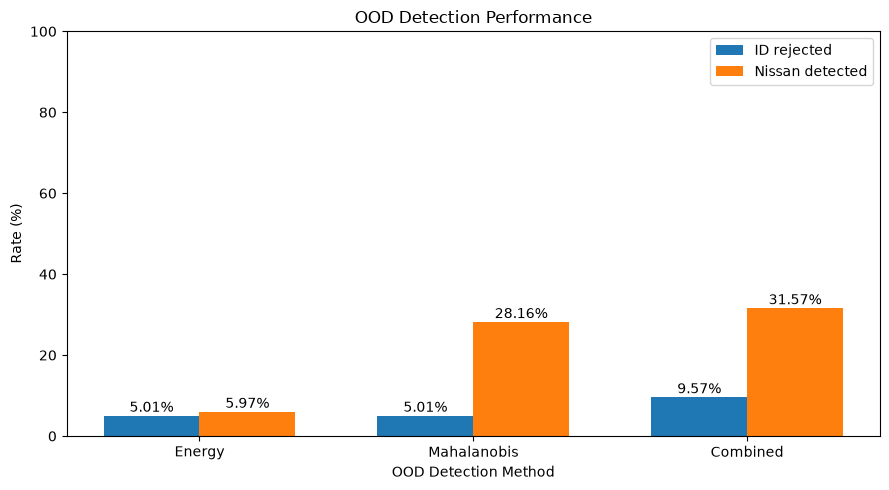

In [22]:
import numpy as np
import matplotlib.pyplot as plt

# ID rejection on validation set
energy_id_rejection = (
    (val_energy > energy_threshold).float().mean().item() * 100
)

maha_id_rejection = (
    (val_maha > maha_threshold).float().mean().item() * 100
)

# Combined ID rejection
combined_val_ood = (
    (val_energy > energy_threshold) |
    (val_maha > maha_threshold)
)

combined_id_rejection = (
    combined_val_ood.float().mean().item() * 100
)

# Nissan OOD detection
energy_nissan_detection = (
    neysan_energy_ood.float().mean().item() * 100
)

maha_nissan_detection = (
    neysan_maha_ood.float().mean().item() * 100
)

combined_nissan_detection = (
    combined_ood.float().mean().item() * 100
)

methods = ["Energy", "Mahalanobis", "Combined"]

id_rejected = [
    energy_id_rejection,
    maha_id_rejection,
    combined_id_rejection
]

nissan_detected = [
    energy_nissan_detection,
    maha_nissan_detection,
    combined_nissan_detection
]

x = np.arange(len(methods))
width = 0.35

plt.figure(figsize=(9, 5))

bars1 = plt.bar(
    x - width/2,
    id_rejected,
    width,
    label="ID rejected"
)

bars2 = plt.bar(
    x + width/2,
    nissan_detected,
    width,
    label="Nissan detected"
)

plt.xticks(x, methods)
plt.ylabel("Rate (%)")
plt.xlabel("OOD Detection Method")
plt.title("OOD Detection Performance")

plt.ylim(0, 100)
plt.legend()

# Add values above bars
for bars in [bars1, bars2]:
    for bar in bars:
        value = bar.get_height()
        plt.text(
            bar.get_x() + bar.get_width()/2,
            value + 1,
            f"{value:.2f}%",
            ha="center"
        )

plt.tight_layout()
plt.show()

In [ ]:
model.eval()

unknown_missed = []

with torch.no_grad():

    for images, image_names in unseen_loader:

        images = images.to(DEVICE)

        # -------------------------
        # Classification
        # -------------------------
        logits = model(images)

        probabilities = torch.softmax(logits, dim=1)

        confidence, predictions = probabilities.max(dim=1)

        # -------------------------
        # Energy
        # -------------------------
        energy = energy_score(logits)

        # -------------------------
        # Mahalanobis
        # -------------------------
        features = extract_features(model, images)

        maha_distance, _ = mahalanobis_score(
            features,
            class_means.to(DEVICE),
            torch.tensor(
                precision,
                dtype=torch.float32,
                device=DEVICE
            )
        )

        # -------------------------
        # OOD decisions
        # -------------------------
        energy_ood = energy > energy_threshold
        maha_ood = maha_distance > maha_threshold

        # Combined detector
        combined_ood = energy_ood | maha_ood

        # -------------------------
        # Keep Nissan images that
        # were NOT detected as OOD
        # -------------------------
        for i, (image, name, pred, conf, e, m) in enumerate(
            zip(
                images,
                image_names,
                predictions,
                confidence,
                energy,
                maha_distance
            )
        ):

            if not combined_ood[i].item():

                unknown_missed.append({
                    "image": image.cpu(),
                    "name": name,
                    "pred": pred.cpu().item(),
                    "confidence": conf.cpu().item(),
                    "energy": e.cpu().item(),
                    "maha": m.cpu().item()
                })

print(
    "Nissan images missed by Combined OOD detector:",
    len(unknown_missed)
)

C:\Users\Setayesh\AppData\Local\Temp\ipykernel_21436\2314138837.py:33: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.tensor(


Nissan images missed by Combined OOD detector: 401


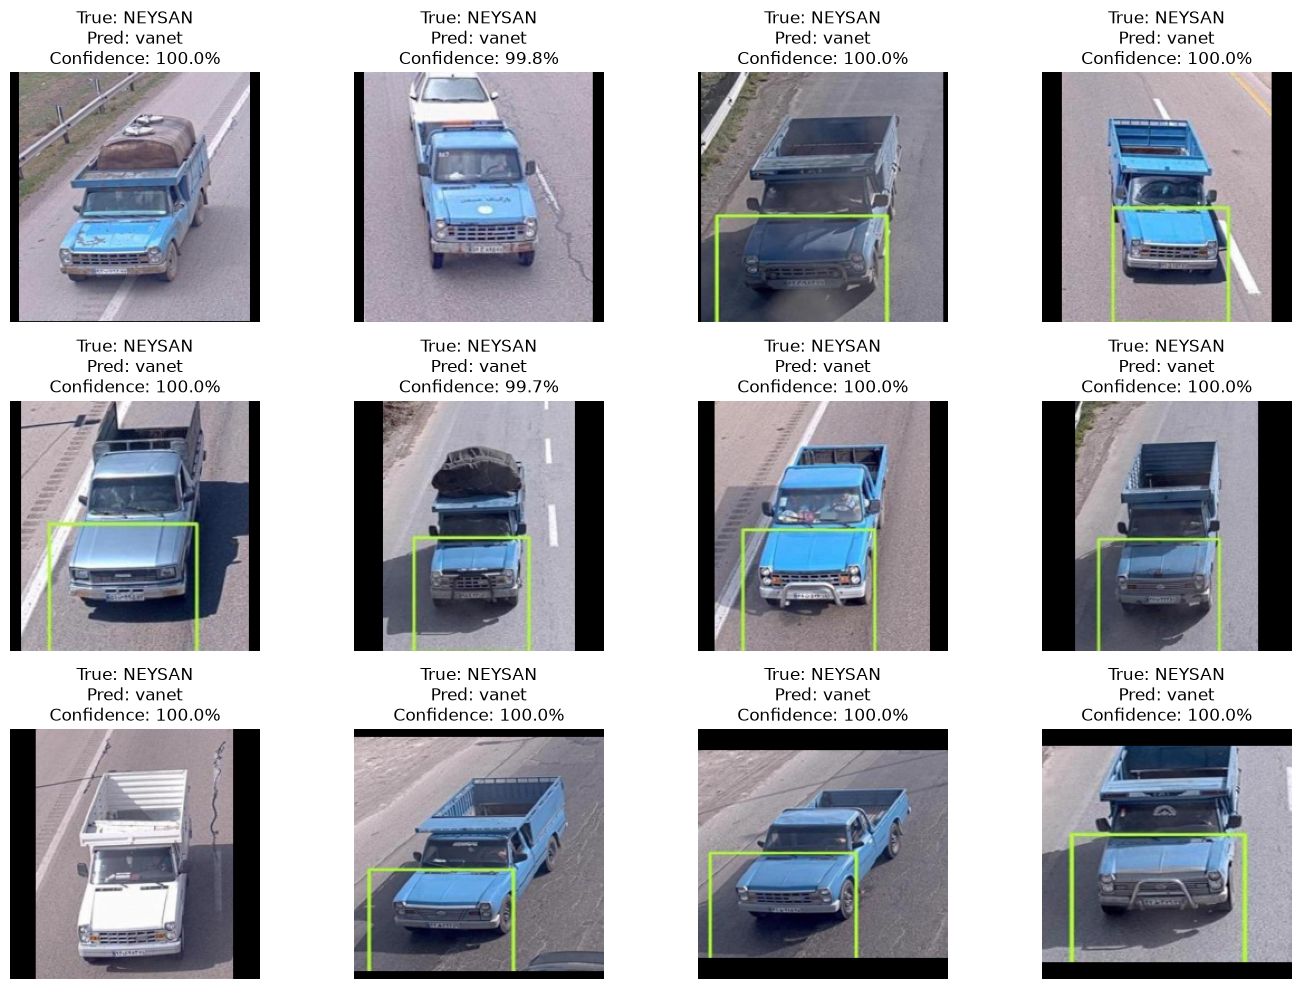

In [24]:
import matplotlib.pyplot as plt
import numpy as np

class_names = [
    "ambulance",
    "autobus",
    "kamyun",
    "kamyunet",
    "minibus",
    "savari",
    "taxi",
    "vanet"
]

num_images = min(12, len(unknown_missed))

fig, axes = plt.subplots(3, 4, figsize=(14, 10))
axes = axes.flatten()

mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])

for i in range(num_images):

    item = unknown_missed[i]

    image = item["image"]

    # Undo ImageNet normalization
    image = image.permute(1, 2, 0).numpy()
    image = image * std + mean
    image = np.clip(image, 0, 1)

    axes[i].imshow(image)

    pred_class = class_names[item["pred"]]
    confidence = item["confidence"] * 100

    axes[i].set_title(
        f"True: NEYSAN\n"
        f"Pred: {pred_class}\n"
        f"Confidence: {confidence:.1f}%"
    )

    axes[i].axis("off")

# Hide unused axes
for i in range(num_images, len(axes)):
    axes[i].axis("off")

plt.tight_layout()
plt.show()

### Needs_Review and Unknown Detection

In [25]:
model.eval()

unknown_samples = []
review_samples = []
ood_missed_samples = []
confidence_threshold = 0.70

with torch.no_grad():

    for images, image_names in unseen_loader:

        images = images.to(DEVICE)

        # -------------------------
        # Classification
        # -------------------------
        logits = model(images)

        probabilities = torch.softmax(logits, dim=1)

        confidence, predictions = probabilities.max(dim=1)

        # -------------------------
        # Energy
        # -------------------------
        energy = energy_score(logits)

        # -------------------------
        # Mahalanobis
        # -------------------------
        features = extract_features(model, images)

        maha_distance, _ = mahalanobis_score(
            features,
            class_means.to(DEVICE),
            torch.tensor(
                precision,
                dtype=torch.float32,
                device=DEVICE
            )
        )

        # -------------------------
        # OOD decisions
        # -------------------------
        energy_ood = energy > energy_threshold
        maha_ood = maha_distance > maha_threshold

        # -------------------------
        # Process each image
        # -------------------------
        for i, (image, name, pred, conf, e, m) in enumerate(
            zip(
                images,
                image_names,
                predictions,
                confidence,
                energy,
                maha_distance
            )
        ):

            e_ood = energy_ood[i].item()
            m_ood = maha_ood[i].item()
            conf_value = conf.item()

            # -------------------------
            # Final decision
            # -------------------------

            if e_ood and m_ood:

                status = "unknown"

            elif e_ood or m_ood:

                status = "needs_review"

            elif conf_value < confidence_threshold:

                status = "needs_review"

            else:

                # Nissan was accepted as a known image
                status = "known_failure"

            sample = {
                "image": image.cpu(),
                "name": name,
                "pred": pred.item(),
                "confidence": conf_value,
                "energy": e.item(),
                "maha": m.item(),
                "energy_ood": e_ood,
                "maha_ood": m_ood,
                "status": status
            }

            # -------------------------
            # Store result
            # -------------------------

            if status == "unknown":
                unknown_samples.append(sample)

            elif status == "needs_review":
                review_samples.append(sample)

            else:
                ood_missed_samples.append(sample)

print("Unknown:", len(unknown_samples))
print("Needs review:", len(review_samples))
print("OOD missed:", len(ood_missed_samples))

C:\Users\Setayesh\AppData\Local\Temp\ipykernel_21436\986028487.py:36: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.tensor(


Unknown: 15
Needs review: 170
OOD missed: 401


### Error Analysis

In [26]:
from collections import Counter

pred_counts = Counter(
    sample["pred"]
    for sample in ood_missed_samples
)

for class_idx, count in pred_counts.most_common():
    print(
        f"{class_names[class_idx]:10s} : {count}"
    )

vanet      : 401


In [27]:
from collections import defaultdict
import numpy as np

class_confidences = defaultdict(list)

for sample in ood_missed_samples:

    pred_class = class_names[sample["pred"]]

    class_confidences[pred_class].append(
        sample["confidence"]
    )

for class_name, confidences in class_confidences.items():

    print(
        f"{class_name:10s} | "
        f"Count: {len(confidences):3d} | "
        f"Mean confidence: {np.mean(confidences):.2%} | "
        f"Max confidence: {np.max(confidences):.2%} | "
        f"Min confidence: {np.min(confidences):.2%}"
    )

vanet      | Count: 401 | Mean confidence: 99.95% | Max confidence: 100.00% | Min confidence: 97.08%
